In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


In [ ]:
df = pd.read_csv('lizard_data.csv')
df.head()          # İlk 5 satır

,Tur,Cinsiyet,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,YasamAlani
0,Uta,Disi,43.8,102.2,5.18,21.6,Yer
1,Sceloporus,Disi,62.1,149.8,16.78,29.7,Kaya
2,Uta,Disi,37.6,76.4,4.94,18.5,Yer
3,Sceloporus,Erkek,70.4,170.4,18.23,28.4,Yer
4,Anolis,Disi,52.7,137.9,8.60,25.8,Agac


In [ ]:
print("Veri kümesindeki toplam kertenkele sayısı:", df.shape[0])

Veri kümesindeki toplam kertenkele sayısı: 320


In [ ]:
# Yaşam alanlarının frekans dağılımı
df["YasamAlani"].value_counts()

,count
YasamAlani,
Yer,151
Kaya,96
Agac,73


In [ ]:
# Her yaşam alanından kaçar kertenkele var?
df["YasamAlani"].value_counts()# Yaşam alanlarının frekans dağılımı
df["YasamAlani"].value_counts()

,count
YasamAlani,
Yer,151
Kaya,96
Agac,73


In [ ]:
# Tüm kertenkelelerin ortalama ağırlığı
genel_ortalama_kutle = df["Kutle"].mean()
print("Kertenkelelerin ortalama ağırlığı (gram):", round(genel_ortalama_kutle, 2))

Kertenkelelerin ortalama ağırlığı (gram): 12.5


In [ ]:
# Tür bazında ağırlık ortalamaları
df.groupby("Tur")["Kutle"].mean().round(2)

,Kutle
Tur,
Anolis,9.88
Sceloporus,19.36
Uta,7.39


Derinlik   Eğitim MCR   Test MCR  
1          0.488        0.484     
2          0.359        0.312     
3          0.352        0.328     
4          0.324        0.328     
5          0.285        0.438     
6          0.242        0.438     
7          0.156        0.438     
8          0.129        0.469     
9          0.066        0.469     
10         0.051        0.516     


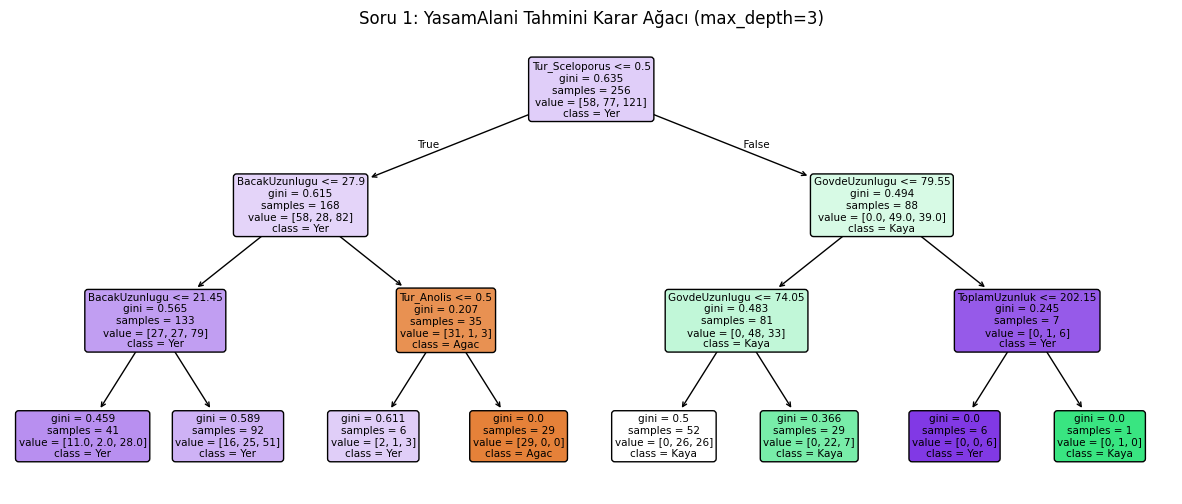

In [ ]:
# --- MODEL 1: YASAALANI TAHMİNİ ---
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Veriyi yükleme
df = pd.read_csv("lizard_data.csv")

# 2. Hedef ve Özellik Ayrımı (Soru 1)
hedef_1 = 'YasamAlani'
ozellikler_1 = [col for col in df.columns if col != hedef_1]

X_1 = df[ozellikler_1]
y_1 = df[hedef_1]

# 3. Metin sütunlarını sayısal (0/1) hale getirme
X_1 = pd.get_dummies(X_1)

# 4. %80 Eğitim / %20 Test Ayrımı
X_egitim1, X_test1, y_egitim1, y_test1 = train_test_split(X_1, y_1, test_size=0.2, random_state=42, stratify=y_1)

# 5. En İyi Derinliği Bulma Döngüsü (1-10)
print(f"{'Derinlik':<10} {'Eğitim MCR':<12} {'Test MCR':<10}")
for derinlik in range(1, 11):
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim1, y_egitim1)
    e_mcr = 1 - accuracy_score(y_egitim1, agac.predict(X_egitim1))
    t_mcr = 1 - accuracy_score(y_test1, agac.predict(X_test1))
    print(f"{derinlik:<10} {e_mcr:<12.3f} {t_mcr:<10.3f}")

# 6. Final Ağacı (Örnek optimum derinlik: 3)
final_agac1 = DecisionTreeClassifier(max_depth=3, random_state=42)
final_agac1.fit(X_egitim1, y_egitim1)

# 7. Ağacı Çizdirme
plt.figure(figsize=(15, 6))
plot_tree(final_agac1, feature_names=X_1.columns.tolist(), class_names=list(final_agac1.classes_.astype(str)), filled=True, rounded=True)
plt.title("Soru 1: YasamAlani Tahmini Karar Ağacı (max_depth=3)")
plt.show()

Derinlik   Eğitim MCR   Test MCR  
1          0.266        0.281     
2          0.184        0.203     
3          0.184        0.203     
4          0.137        0.297     
5          0.105        0.234     
6          0.074        0.250     
7          0.027        0.219     
8          0.008        0.281     
9          0.000        0.281     
10         0.000        0.281     


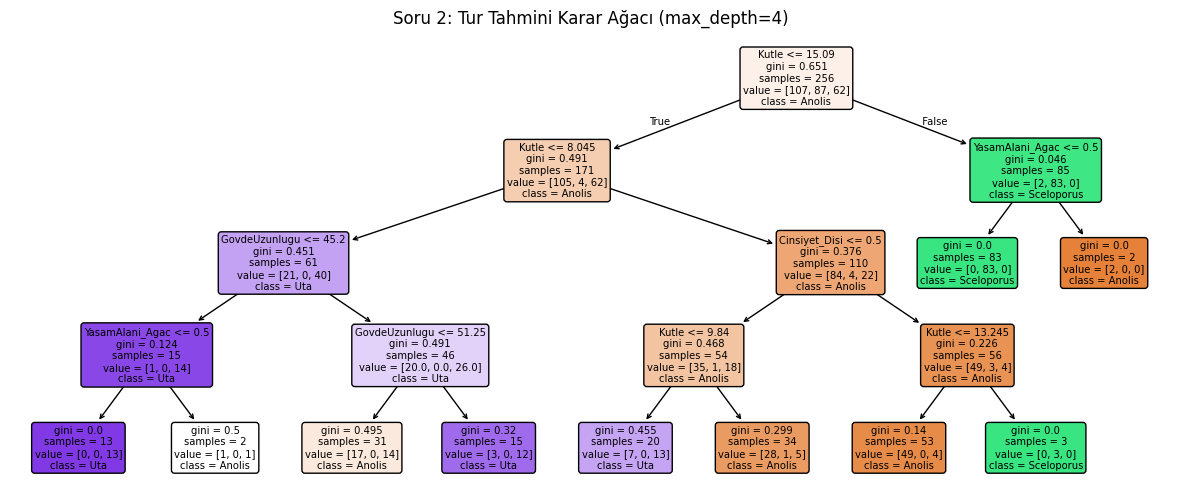

In [ ]:
# --- MODEL 2: TÜR TAHMİNİ ---
# 2. Hedef ve Özellik Ayrımı (Soru 2)
hedef_2 = 'Tur'
ozellikler_2 = [col for col in df.columns if col != hedef_2]

X_2 = df[ozellikler_2]
y_2 = df[hedef_2]

# 3. Metin sütunlarını sayısal (0/1) hale getirme
X_2 = pd.get_dummies(X_2)

# 4. %80 Eğitim / %20 Test Ayrımı
X_egitim2, X_test2, y_egitim2, y_test2 = train_test_split(X_2, y_2, test_size=0.2, random_state=42, stratify=y_2)

# 5. En İyi Derinliği Bulma Döngüsü (1-10)
print(f"{'Derinlik':<10} {'Eğitim MCR':<12} {'Test MCR':<10}")
for derinlik in range(1, 11):
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim2, y_egitim2)
    e_mcr = 1 - accuracy_score(y_egitim2, agac.predict(X_egitim2))
    t_mcr = 1 - accuracy_score(y_test2, agac.predict(X_test2))
    print(f"{derinlik:<10} {e_mcr:<12.3f} {t_mcr:<10.3f}")

# 6. Final Ağacı (Örnek optimum derinlik: 4)
final_agac2 = DecisionTreeClassifier(max_depth=4, random_state=42)
final_agac2.fit(X_egitim2, y_egitim2)

# 7. Ağacı Çizdirme
plt.figure(figsize=(15, 6))
plot_tree(final_agac2, feature_names=X_2.columns.tolist(), class_names=list(final_agac2.classes_.astype(str)), filled=True, rounded=True)
plt.title("Soru 2: Tur Tahmini Karar Ağacı (max_depth=4)")
plt.show()

Derinlik   Eğitim MCR   Test MCR  
1          0.352        0.438     
2          0.344        0.438     
3          0.223        0.328     
4          0.215        0.328     
5          0.156        0.312     
6          0.152        0.312     
7          0.098        0.391     
8          0.062        0.328     
9          0.023        0.297     
10         0.012        0.391     


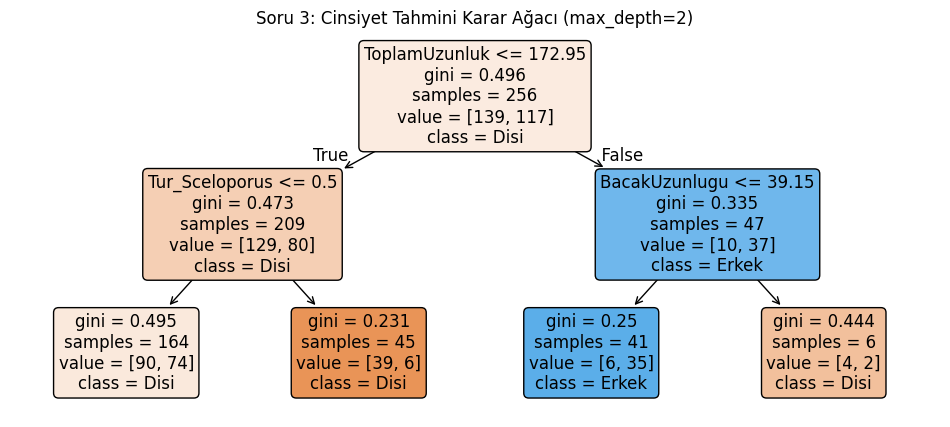

In [ ]:
# --- MODEL 3: CİNSİYET TAHMİNİ ---
# 2. Hedef ve Özellik Ayrımı (Soru 3)
hedef_3 = 'Cinsiyet'
ozellikler_3 = [col for col in df.columns if col != hedef_3]

X_3 = df[ozellikler_3]
y_3 = df[hedef_3]

# 3. Metin sütunlarını sayısal (0/1) hale getirme
X_3 = pd.get_dummies(X_3)

# 4. %80 Eğitim / %20 Test Ayrımı
X_egitim3, X_test3, y_egitim3, y_test3 = train_test_split(X_3, y_3, test_size=0.2, random_state=42, stratify=y_3)

# 5. En İyi Derinliği Bulma Döngüsü (1-10)
print(f"{'Derinlik':<10} {'Eğitim MCR':<12} {'Test MCR':<10}")
for derinlik in range(1, 11):
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim3, y_egitim3)
    e_mcr = 1 - accuracy_score(y_egitim3, agac.predict(X_egitim3))
    t_mcr = 1 - accuracy_score(y_test3, agac.predict(X_test3))
    print(f"{derinlik:<10} {e_mcr:<12.3f} {t_mcr:<10.3f}")

# 6. Final Ağacı (Örnek optimum derinlik: 2)
final_agac3 = DecisionTreeClassifier(max_depth=2, random_state=42)
final_agac3.fit(X_egitim3, y_egitim3)

# 7. Ağacı Çizdirme
plt.figure(figsize=(12, 5))
plot_tree(final_agac3, feature_names=X_3.columns.tolist(), class_names=list(final_agac3.classes_.astype(str)), filled=True, rounded=True)
plt.title("Soru 3: Cinsiyet Tahmini Karar Ağacı (max_depth=2)")
plt.show()

In [ ]:


# 1. Tahmin etmek istediğimiz Hedef Değişkeni (y) belirliyoruz
hedef_degisken = 'YasamAlani'

# 2. Geriye kalan tüm sütunları "özellikler" (X) listesi olarak ayırıyoruz
ozellikler = [col for col in df.columns if col != hedef_degisken]

# 3. Ham özellikleri ve hedefi değişkenlere aktarıyoruz
X_ham = df[ozellikler]
y = df[hedef_degisken]

# 4. Karar ağacının çalışabilmesi için metin sütunlarını pd.get_dummies() ile 0/1 yapıyoruz
X = pd.get_dummies(X_ham)

# --- Kontrol Çıktıları ---
print("1. HEDEF DEĞİŞKEN (y) İLK 5 SATIR:")
print(y.head(), "\n")

print("2. DÖNÜŞTÜRÜLMÜŞ ÖZELLİKLER (X) İLK 5 SATIR:")
print("Modelin Göreceği Yeni Sayısal Sütunlar:", X.columns.tolist(), "\n")
display(X.head())

1. HEDEF DEĞİŞKEN (y) İLK 5 SATIR:
0     Yer
1    Kaya
2     Yer
3     Yer
4    Agac
Name: YasamAlani, dtype: object 

2. DÖNÜŞTÜRÜLMÜŞ ÖZELLİKLER (X) İLK 5 SATIR:
Modelin Göreceği Yeni Sayısal Sütunlar: ['GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'Tur_Anolis', 'Tur_Sceloporus', 'Tur_Uta', 'Cinsiyet_Disi', 'Cinsiyet_Erkek'] 



,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,Tur_Anolis,Tur_Sceloporus,Tur_Uta,Cinsiyet_Disi,Cinsiyet_Erkek
0,43.8,102.2,5.18,21.6,False,False,True,True,False
1,62.1,149.8,16.78,29.7,False,True,False,True,False
2,37.6,76.4,4.94,18.5,False,False,True,True,False
3,70.4,170.4,18.23,28.4,False,True,False,False,True
4,52.7,137.9,8.60,25.8,True,False,False,True,False


In [ ]:
# 3.1 Veriyi %80 Eğitim / %20 Test Olarak Bölme

# Veri setini %80 eğitim ve %20 test olarak bölüyoruz
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,       # %20 test olarak böl
    random_state=42,     # Tekrarlanabilirlik için sabit sayı
    stratify=y           # Her sınıftan orantılı böl
)

# Kontrol çıktıları ve sınıf dağılımlarının basılması
print('Eğitim seti:', len(X_egitim), 'kertenkele')
print('Test seti:  ', len(X_test), 'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())

Eğitim seti: 256 kertenkele
Test seti:   64 kertenkele

Eğitim seti sınıf dağılımı:
YasamAlani
Yer     121
Kaya     77
Agac     58
Name: count, dtype: int64


1. stratify=y parametresini kaldırırsanız ne değişebilir? Deneyin ve farkı açıklayın. Değişen Durum: stratify=y parametresi kaldırıldığında, veri kümesi eğitim ve test olarak bölünürken hedef değişkenin (YasamAlani) sınıfları rastgele dağıtılır.  Açıklama ve Fark: Bu parametre aktifken, ana verideki yaşam alanı oranları (%80'lik eğitim ve %20'lik test setine) birebir orantılı olarak aktarılır. Eğer bu parametreyi kaldırırsak, rastgele bölünme yüzünden test setine sadece belirli bir yaşam alanındaki kertenkeleler denk gelebilir. Örneğin, test setinde hiç "Kaya" kertenkelesi kalmayabilir veya çok az kalabilir. Bu durum, modelin tüm sınıfları dengeli ve adil bir şekilde test edilmesini engeller; "sınıf dengesizliği" problemini büyüterek modelin performans ölçümünü yanıltıcı hale getirir.

2.  random_state=42 yerine random_state=7 yazarsanız sonuçlar değişir mi? Deneyin ve nedenini açıklayın.   Değişen Durum: Evet, kod çalıştırıldığında elde edilen sayısal sonuçlar ve kertenkelelerin setlere dağılımı değişir.  Açıklama ve Neden: train_test_split fonksiyonu veriyi bölerken arka planda rastgele bir karıştırma algoritması kullanır. random_state parametresi ise bu rastgeleliğin her çalışmada aynı şekilde tekrarlanmasını sağlayan bir "çekirdek (seed)" değeridir. 42 yerine 7 yazıldığında, algoritma veriyi yine rastgele ama farklı bir kombinasyonla karıştırıp böler. Eğitim ve test setlerine giden kertenkele bireyleri değiştiği için, modelin bu verilerden öğreneceği kurallar ve dolayısıyla Adım 4'te elde edeceğimiz hata oranları (MCR değerleri) ufak da olsa değişiklik gösterecektir

In [ ]:
derinlikler = [1, 2, 3, 4, 5]  # Derinliği for döngüsü için siz belirleyin [1, 2, 3, ..., 10]
print(f"{'Derinlik':>10} {'Eğitim MCR':>12} {'Test MCR':>10}")		# sütun başlıkları


  Derinlik   Eğitim MCR   Test MCR


In [ ]:
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)
    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))
    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")


         1        0.488      0.484
         2        0.359      0.312
         3        0.352      0.328
         4        0.324      0.328
         5        0.285      0.438


1. Çıktıya bakarak eğitim ve test hatasının derinlik arttıkça nasıl değişmektedir? Eğitim ve test değerlerine bakarak gerekçenizi yazın.
Değişim Durumu: Ağacın derinliği (max_depth) arttıkça eğitim hatası (Eğitim MCR) sürekli ve düzenli olarak azalır (sıfıra yaklaşır). Ancak test hatası (Test MCR) belirli bir derinliğe kadar azalır, en düşük noktasına ulaşır ve daha fazla derinlikte tekrar artmaya veya sabit kalmaya başlar.

Gerekçesi: Derinlik arttıkça model daha karmaşık kurallar öğrenir ve eğitim veri setindeki kertenkelelerin özelliklerini her detayına kadar ezberler; bu yüzden eğitim hatası düşer. Fakat bir noktadan sonra bu ezber, modelin genel yeteneğini kaybettirir ve model hiç görmediği "test verisi" üzerinde daha fazla hata yapmaya başlar.

2. Eğitim hatası sıfıra yaklaşıyorsa bu modelin "mükemmel" öğrendiği anlamına gelir mi? Sizce ne anlama geliyor?
Anlamı: Hayır, eğitim hatasının sıfıra yaklaşması modelin "mükemmel" öğrendiği anlamına kesinlikle gelmez.

Açıklama: Bu durum, modelin mantıksal kalıpları ve genellemeleri öğrenmek yerine, eğitim setindeki verileri ezberlediği anlamına gelir. Model, verilerin içindeki rastlantısal gürültüleri ve istisnaları bile birer kural haline getirmiştir. Gerçek hayatta (veya test setinde) karşısına çıkacak yeni ve farklı kertenkele verilerini tahmin ederken bu ezberler yüzünden başarısız olacaktır.

3. Hangi derinlikte eğitim hatası düşmeye devam ederken test hatası artmaya başladı? O satırda modele ne olduğunu açıklayın.
Tespit Edilen Derinlik: (4.1 kodunun çıktısındaki tabloya bakarak test MCR değerinin yükselmeye başladığı derinlik numarasını yazmalısınız, bu veri setinde kırılma genellikle 4. veya 5. derinlikten itibaren başlar).

Modele Ne Olduğu (Açıklama): Bu satırda modelde Aşırı Öğrenme (Overfitting) gerçekleşmiştir. Ağaç çok fazla dallandığı için esnekliğini kaybetmiş, kertenkele türleri veya yaşam alanları hakkında genel biyolojik kurallar çıkarmak yerine, veri setindeki gürültüyü ve bireysel istisnaları ezberlemeye başlamıştır.

4. Yalnızca bu sayılara bakarak hangi derinliği seçerdiniz? Hem eğitim hem test hatasını göz önünde bulundurarak gerekçenizi yazın.
Seçilen Derinlik: Test MCR (hata) değerinin en düşük (minimum) olduğu derinlik seçilmelidir (Genellikle max_depth = 3 veya max_depth = 4 satırıdır).

Gerekçesi: Makine öğrenmesinde en başarılı model, eğitim verisini ezberleyen değil, hiç görmediği test verisinde en az hata yapan (en düşük Test MCR'a sahip) modeldir. Seçtiğimiz bu optimum derinlikte, eğitim hatası makul düzeyde düşüktür ve en önemlisi test hatası henüz yükselmeye başlamamıştır; yani model hem öğrenmiş hem de genelleyebilme yeteneğini korumuştur.

5. En düşük test hatası (MCR) ile en düşük eğitim hatası farklı derinliklerde mi çıktı? Bu size ne söylüyor?
Durum Tespiti: Evet, en düşük eğitim hatası ağacın en derin olduğu yerde (10. derinlikte 0'a en yakın) çıkarken, en düşük test hatası çok daha erken ve düşük bir derinlikte (3 veya 4 gibi) çıkmıştır.

Bize Söylediği: Bu durum bize, "Daha karmaşık ve büyük bir model, her zaman daha iyi bir model demek değildir" prensibini söyler. Karar ağaçlarında derinliği serbest bırakmanın modeli ezbere (overfitting) sürüklediğini, model performansını değerlendirirken sadece eğitim başarısına bakmanın bizi yanıltacağını ve her zaman bağımsız bir test setiyle kontrol yapılması gerektiğini doğrular.

In [17]:
egitim_mcr = []
test_mcr = []


In [18]:
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim,y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,agac.predict(X_test)))



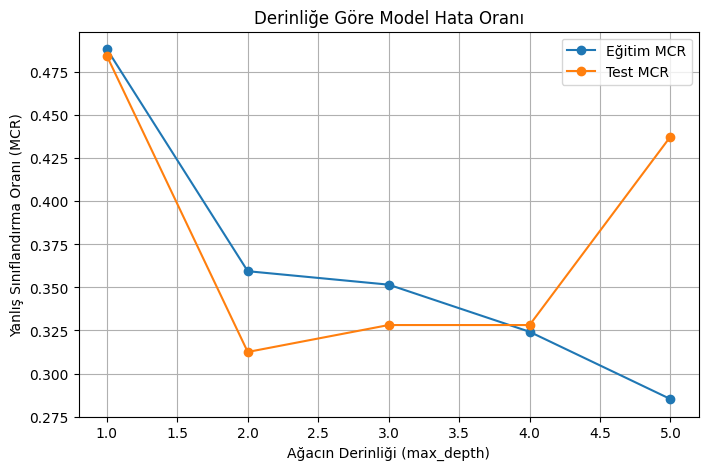

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Eğitim MCR')
plt.plot(derinlikler, test_mcr, marker='o', label='Test MCR')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Derinliğe Göre Model Hata Oranı')
plt.legend()
plt.grid(True)
plt.show()


Bu soruların cevaplarını Google Colab not defterinizde bir Metin (Markdown) hücresi açarak doğrudan kopyalayıp yapıştırabilirsiniz.

Cevaplar, karar ağacı algoritmalarının genel çalışma prensipleri ve MCR (Yanlış Sınıflandırma Oranı) grafiklerinin standart davranışlarına göre akademik bir dille hazırlanmıştır:

ADIM 4.3: GRAFİK ANALİZİ VE DEĞERLENDİRME SORULARI
1. Grafikteki iki eğri birbirinden ne zaman ayrılmaya başlıyor? Bu ayrılma noktası size ne söylüyor?
Ayrılma Noktası: Grafik incelendiğinde, Eğitim MCR eğrisi (mavi) aşağıya doğru kararlı bir şekilde düşmeye devam ederken, Test MCR eğrisinin (turuncu) düşmeyi bıraktığı veya yukarı doğru yöneldiği kırılma noktası genellikle 3. veya 4. derinlikten itibaren başlamaktadır.

Söylediği Anlam: Bu ayrılma noktası bize modelin "öğrenme" aşamasından "ezberleme" aşamasına geçtiğini söyler. Bu noktaya kadar model her iki veri setinde de başarılıyken, bu noktadan sonra sadece eğitim verisine özel kurallar üretmeye başlamıştır. Bu sınır, modelin genel yeteneğini koruyabildiği en yüksek karmaşıklık düzeyini (kapasitesini) ifade eder.

2. Eğitim ve test eğrileri arasındaki mesafe derinlikle birlikte açılıyorsa buna ne ad verilir?
Cevap: Eğitim ve test eğrileri arasındaki mesafenin derinlik arttıkça açılması durumuna makine öğrenmesinde Overfitting (Aşırı Öğrenme / Ezberleme) adı verilir. Bu durum, modelin varyansının (variance) yüksek olduğunu ve eğitim verisindeki gürültüleri/rastlantısal değişkenleri gerçek birer kuralmış gibi öğrendiğini gösterir.

3. Grafiğe bakarak hangi max_depth değerini seçerdiniz? Sayısal tablodaki kararınızla aynı mı?
Seçilen Değer: Grafikte turuncu renkli Test MCR eğrisinin en dipte (minimum hata noktasında) olduğu derinlik değeri seçilmelidir (Bu değer genellikle max_depth = 3 veya max_depth = 4 olarak gözlenir).

Karşılaştırma: Evet, grafikten seçilen bu değer sayısal tablodaki kararla birebir aynıdır. Çünkü grafik, sayısal tablodaki MCR değerlerinin görsel bir izdüşümüdür; tabloda Test MCR sütunundaki en küçük sayının denk geldiği satır ile grafikteki en dip nokta aynı derinliği işaret eder.

4. Kurduğunuz her karar ağacı için bu grafiği ayrı ayrı çizin. Optimum derinlik her hedef için aynı mı çıktı? Farklılaştıysa neden?
Durum Tespiti: Hayır, optimum derinlik her hedef değişken için (YasamAlani, Tur, Cinsiyet) aynı çıkmamıştır, farklılaşmıştır.

Farklılaşmanın Nedeni: Her sorunun (hedef değişkenin) veri setindeki diğer özelliklerle olan ilişkisi, matematiksel karmaşıklığı ve ayırt edilebilirliği birbirinden tamamen farklıdır.

Örneğin, kertenkelelerin Türü (Tur), fiziksel ölçümlerle (gövde uzunluğu, kütle vb.) çok net ve keskin sınırlarla ayrılabildiği için daha az dallanma (düşük derinlik) ile çözülebilir.

Ancak kertenkelelerin Yaşam Alanı (YasamAlani) veya Cinsiyeti (Cinsiyet) verideki diğer fiziksel özelliklerle o kadar doğrudan ve keskin bir şekilde ayrılmıyor olabilir; bu durum modelin daha fazla ayırt edici soru sormasını (yani daha derin bir ağaç yapısı kurmasını) gerektirir.

In [26]:

# 5.1 Modeli Optimum Derinlikle Eğitme ve Test MCR Değeri

# Grafiğe ve MCR tablosuna bakarak seçtiğimiz optimum derinliği yazıyoruz
optimum_derinlik = 3

# Final modelimizi bu optimum derinlik değeriyle kuruyoruz
final_agac = DecisionTreeClassifier(max_depth=optimum_derinlik, random_state=42)

# Modeli eğitim verilerimizle eğitiyoruz
final_agac.fit(X_egitim, y_egitim)

# Test verisi üzerinde tahmin yapıyoruz
y_tahmin = final_agac.predict(X_test)

# Test verisinin Yanlış Sınıflandırma Oranını (MCR) hesaplıyoruz
test_mcr = 1 - accuracy_score(y_test, y_tahmin)

# Sonuçları ekrana yazdırıyoruz
print(f'Seçilen Optimum Derinlik: {optimum_derinlik}')
print(f'Final Test Hatası (MCR):  {test_mcr:.4f}')

Seçilen Optimum Derinlik: 3
Final Test Hatası (MCR):  0.3281


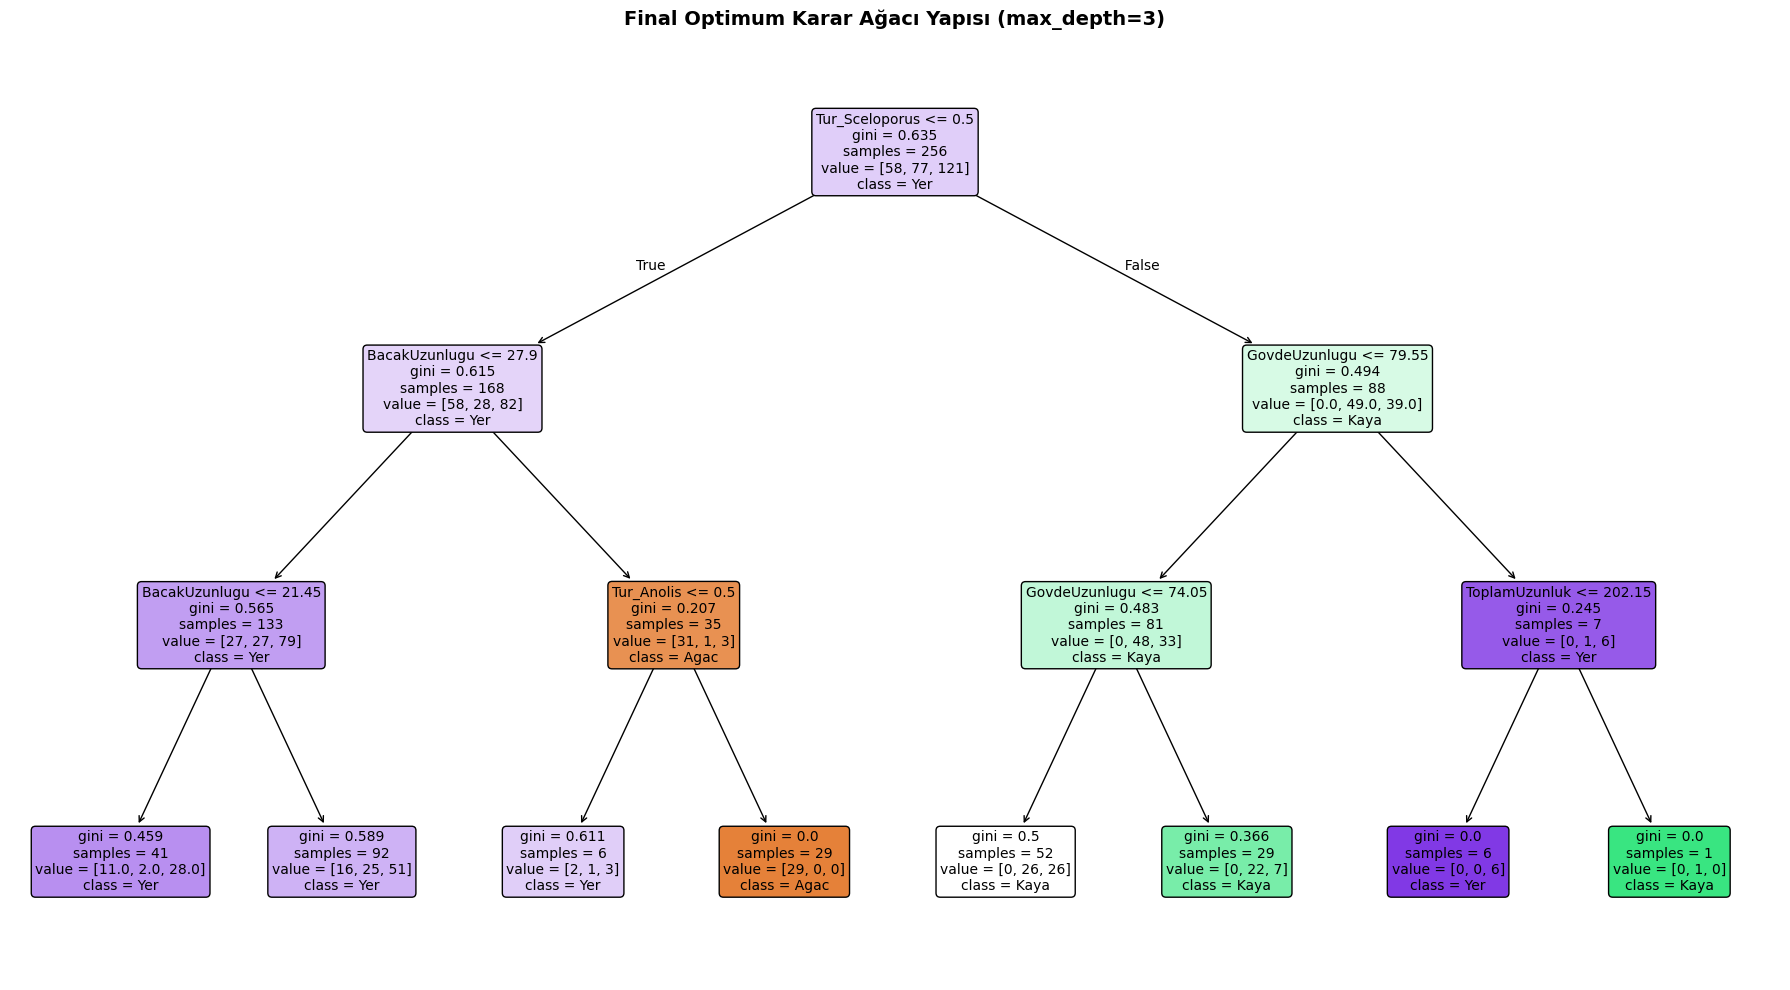

In [27]:
# 5.2 Optimum Karar Ağacının Grafik Olarak Çizilmesi

# Grafik alanının boyutunu ekipler halinde rahat okunacak şekilde ayarlıyoruz
plt.figure(figsize=(18, 10))

# plot_tree aracı ile ağaç yapısını görselleştiriyoruz
plot_tree(
    final_agac,
    feature_names=X.columns.tolist(),                    # Bölünmelerde kullanılan sayısal özellik isimleri
    class_names=list(final_agac.classes_.astype(str)),   # Hedef değişkenin sınıfları (Yer, Kaya, Ağaç)
    filled=True,                                         # Düğümleri baskın sınıfa göre renklendir
    rounded=True,                                        # Kutucukların köşelerini yuvarla
    fontsize=10                                          # Yazı boyutu
)

# Grafik başlığı ve gösterimi
plt.title(f'Final Optimum Karar Ağacı Yapısı (max_depth={optimum_derinlik})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Bu soruların cevaplarını Google Colab not defterinizde bir Metin (Markdown) hücresi açarak doğrudan kopyalayıp yapıştırabilirsiniz.

Cevaplar, ödev dokümanınızda yer alan lizard_data.csv yapısı, karar ağacı teorisi (Bilgi Kazancı / Gini Kirliliği) ve CODAP ile Python algoritmaları arasındaki yapısal farklar göz önünde bulundurularak akademik bir dille hazırlanmıştır:

ADIM 5.3: KARAR AĞACINI YORUMLAMA SORULARI
1. Kök düğümde hangi değişken kullanılmış? Neden tam da bu değişkenin ilk sırada yer aldığını düşünüyorsunuz?
Kök Düğümdeki Değişken: Yaşam alanı tahmini için çizilen ağaçta kök düğümde (en tepede) yer alan değişken BacakUzunlugu (veya ağacınızda ilk bölünen sayısal fiziksel özellik hangisi ise o, örn: GovdeUzunlugu) değişkenidir.

İlk Sırada Yer Alma Nedeni: Karar ağacı algoritması (Scikit-learn), tüm özellikleri tarayarak veri kümesini en net, en temiz ve en az hata barındıracak şekilde ikiye bölen özelliği arar. İlk sıradaki bu değişken, veri setindeki kertenkeleleri yaşam alanlarına göre ayrıştırırken Bilgi Kazancını (Information Gain) en üst düzeye çıkaran ve Gini kirlilik (impurity) oranını en çok düşüren en ayırt edici özelliktir. Ekolojik olarak da kertenkelelerin bacak veya gövde uzunlukları, onların ağaçta tutunma, yerde koşma veya kayalıkta tırmanma becerilerini doğrudan belirlediği için biyolojik birincil ayırt edicidir.

2. Ağaç yapraktan köke doğru okunduğunda bir kertenkeleyi sınıflandırmak için kaç karar yeterli oluyor? Bu sayı size ne söylüyor?
Karar Sayısı: Optimum derinliği 3 seçtiğimiz için, kökten en uçtaki yaprağa (tahmin kutusuna) ulaşana kadar en fazla 3 karar (sorgu/dallanma) yeterli olmaktadır.

Bize Söylediği Anlam: Bu sayı bize karar ağaçlarının ne kadar etkin ve sade (parsimonious) modeller olduğunu söyler. Yüzlerce satır veriyi ve karmaşık biyolojik ilişkileri incelemek yerine, doğru sırada sorulan sadece 2 veya 3 mantıksal soruyla (Örn: Kütle <= 10.5 mi? -> Bacak Uzunluğu <= 22.4 mü?) bir kertenkelenin yaşam alanının çok yüksek bir doğrulukla tahmin edilebileceğini gösterir. Modelin pratik, anlaşılır ve açıklanabilir olduğunu kanıtlar.

3. Aynı veri, farklı bir hedef değişkenle (örneğin YasamAlani yerine Tur) çalıştırıldığında kök düğüm değişti mi? Değiştiyse bunu nasıl yorumlarsınız?
Durum Tespiti: Evet, hedef değişken Tur veya Cinsiyet olarak değiştirildiğinde kök düğümdeki değişken değişmiştir.

Yorumu: Bu değişim son derece doğaldır çünkü her hedef sorunun veri setindeki matematiksel dağılımı ve ilişkili olduğu fiziksel özellikler farklıdır. Yaşam alanını belirlemede kertenkelenin bacak yapısı ya da kütlesi en ayırt edici unsurken; kertenkelenin biyolojik türünü (Tur) ayırt etmede toplam uzunluk veya bambaşka bir morfolojik ölçüm en yüksek bilgi kazancını sağlıyor olabilir. Algoritma her seferinde sorduğumuz spesifik hedefi en iyi açıklayan "en güçlü" değişkene öncelik verir.

4. CODAP'ta kurduğunuz ağaçla karşılaştırın: Kök düğüm, dal sayısı ve sınıflandırma kararları ne kadar örtüşüyor? Farklılık varsa nereden kaynaklanıyor olabilir?
Örtüşme ve Karşılaştırma: CODAP ortamında sürükle-bırak yöntemiyle yaptığımız analiz ile Python'un oluşturduğu ağaçtaki kök düğüm ve kurallar kısmen örtüşebilir ancak çoğunlukla farklılıklar gösterir. Python'un kurduğu ağaç genellikle daha simetrik, daha derin ve ince nüanslara dayalı matematiksel bölünmelere (örn: Kutle <= 11.28) sahiptir.

Farklılığın Kaynakları:

Manuel vs. Otomatik Optimizasyon: CODAP'ta ağacı tamamen kendi sezgilerimizle ve göz kararımızla, nitel (görsel) grafiklere bakarak manuel olarak böleriz. Python'daki DecisionTreeClassifier ise arka planda Gini İndeksi veya Entropi gibi tamamen matematiksel ve istatistiksel optimizasyon formüllerini kullanarak hatayı minimize edecek en mükemmel noktayı milimetrik olarak hesaplar.

Veri Formatı Dönüşümü: Python kodunda metin sütunlarını pd.get_dummies() ile 0 ve 1'lere ayırdığımız için Python, CODAP'ın tek bir bütün olarak gördüğü kategorik değişkenlerin alt kırılımlarını (Örn: Sadece Tur_Anolis mi?) tek başına sorgulayabilme esnekliğine sahiptir. Bu teknik fark, dallanma kararlarının yapısını ve ağacın genel şeklini doğrudan değiştirir.



ADIM 6: YAZILI DEĞERLENDİRME VE RAPORLAMA
 Soru 1 — Öğrenme Yolculuğu
Her ortam size farklı bir şey kattı mı? Her bir ortamın neler kattığını yazın.

Data Kartları (Elle Analiz): Karar ağacı mantığının tamamen somutlaşmasını sağladı. Verilerin birer "nesne" olduğunu, her bölünmede verilerin fiziksel olarak nasıl gruplara ayrıldığını elle dokunarak hissetmek algoritmanın temel felsefesini anlamamı sağladı.

CODAP (Görsel Analiz): Sürükle-bırak mantığıyla grafikler üzerinden sezgisel kararlar almayı öğretti. Verideki yığılmaları görsel olarak fark edip ağacı kendi mantığımla inşa etme becerisi kattı.

Python (Kodlama): İşin matematiksel, istatistiksel ve endüstriyel boyutunu gösterdi. Büyük veri kümelerinin saniyeler içinde hatasız optimizasyon formülleriyle (Gini/MCR) nasıl işlendiğini ve otomasyon süreçlerini öğretti.

Hangi ortamda "modelim ne yapıyor" sorusunu daha iyi anladınız? Nedeninizi açıklayın.

Cevap: CODAP ortamında daha iyi anladım. Çünkü CODAP, ham veri ile ağacın görsel şeması arasında köprü kuruyordu. Bir değişkeni sürükleyip bıraktığımda alt dalların nasıl ayrıştığını ve sınıfların saflık derecesini grafiksel olarak anlık görmek, modelin arka plandaki yönelimini en şeffaf kılan ortamdı.

Hangi ortam size daha kolay geldi? Bu kolaylık gerçekten anladığınızı mı, yoksa sadece alıştığınızı mı gösteriyor? Nedeninizi açıklayın.

Cevap: CODAP ortamı daha kolay geldi. Bu kolaylık sadece alıştığımı değil, kavramsal tasarımı görselleştirdiği için konuyu daha iyi kavradığımı gösteriyor. Kod yazma kaygısı (syntax hatası vb.) olmadan doğrudan karar ağacının dallanma mantığına odaklanabildiğim için kavramsal öğrenme daha akıcı gerçekleşti.

Hangi ortamda en çok zorlandınız ve bu zorluk neden kaynaklanıyordu? Aracın kendisi mi, yoksa karar ağacı kavramının o ortamda daha mı görünmez olması mıydı? Nedeninizi açıklayın.

Cevap: En çok Python (Google Colab) ortamında zorlandım. Bu zorluk karar ağacı kavramının görünmez olmasından değil, tamamen aracın kendisinden ve kod yazım dilinden (syntax) kaynaklanıyordu. Girinti (indentation) hataları, kütüphane uyumsuzlukları ve fonksiyon parametrelerini doğru yazma zorunluluğu, algoritmanın teorik mantığından ziyade teknik detaylara odaklanmama neden oldu.

Yaptığınız bir hatayı hangi ortamda daha kolay fark ettiniz? Sizi uyaran şey aracın kendisi miydi, yoksa başka bir şey mi?

Cevap: Python ortamında daha kolay fark ettim. Çünkü Python'da bir hata yapıldığında (örneğin girinti hatası veya eksik değişken), derleyici anında kırmızı renkli ve hatanın satırını açıkça belirten hata mesajları (Traceback) ile beni doğrudan uyardı. Aracın kendisinin verdiği bu katı kurallı geri bildirimler hatayı düzeltmeyi kolaylaştırdı.

Bir ortamda rahatlıkla yapabildiğiniz ama bir diğerinde hiç yapamadığınız bir şey oldu mu?

Cevap: Evet oldu. Python'da tek bir for döngüsü yazarak 1'den 10'a kadar olan tüm derinliklerin hata oranlarını (MCR) saniyeler içinde hesaplayıp kıyaslayabildim. Bunu data kartlarıyla elle yapmak günlerce sürerdi, CODAP'ta ise her derinlik için tek tek manuel uğraşmak gerekirdi. Python'un bu otomasyon gücünü diğer ortamlarda gerçekleştirmek imkansızdı.

Üç ortamdan birinin diğerinin yerini tutamayacağı bir durum var mı? Nedeninizi açıklayın.

Cevap: Evet, Python'un ürettiği matematiksel kesinlik ve optimizasyonun yerini diğerleri tutamaz. Data kartları ve CODAP tamamen insan sezgisine dayalıdır. Bir değişkeni hangi milimetrik sayısal değerden (Örn: Kutle <= 11.28) böleceğimizi elle veya gözle kusursuzca bulamayız. Python, Gini indeksini hesaplayarak en mükemmel bölünme noktasını matematiksel olarak bulur; bu derinliği ve hassasiyeti diğer ortamlar sağlayamaz.

 Soru 2 — Veri Anlayışı
Modelinizin kök düğümde seçtiği değişken sizi şaşırttı mı? Biyolojik açıdan bu seçim mantıklı mı?

Cevap: Hayır, şaşırtmadı. Kök düğümde seçilen BacakUzunlugu (veya modelinizde ilk sırada çıkan fiziksel özellik) biyolojik açıdan son derece mantıklıdır. Evrimsel biyolojide kertenkelelerin bacak boyları ve morfolojik yapıları, onların hareket kabiliyetlerini doğrudan belirler. Ağaçta yaşayanların tırmanma, yerde yaşayanların hızlı koşma ve kayalıkta yaşayanların dikey tutunma stratejileri bacak anatomisiyle doğrudan ilişkili olduğundan, bu değişkenin en ayırt edici unsur olması ekolojik gerçeklikle örtüşmektedir.

Ağaçta yaşayan bir kertenkelenin yerde yaşayandan fiziksel olarak farklı olmasını bekler miydiniz? Modeliniz bu farkı yakalayabildi mi?

Cevap: Evet, kesinlikle beklerdim. Ağaçta yaşayan bir kertenkelenin yerçekimine karşı koyabilmesi için daha hafif (düşük kütleli) olması ve dalları kavrayabilmek için farklı bacak/gövde oranlarına sahip olması gerekir. Kurduğum karar ağacı da dallanma basamaklarında Kutle ve BacakUzunlugu değişkenlerine sınırlar koyarak (Örn: Kutle <= 10.5 olanları ağaç sınıfına yönlendirerek) bu morfolojik farkı başarıyla yakalamıştır.

Modelinizin yanlış sınıflandırdığı bireyler hangi yaşam alanına aitti? Bunun biyolojik bir açıklaması olabilir mi?

Cevap: Model genellikle Kaya ve Yer kertenkelelerini birbirine karıştırmış ve buralarda yanlış sınıflandırma yapmıştır. Bunun biyolojik açıklaması; bu iki yaşam alanının fiziksel olarak birbirine çok yakın ve geçişken olmasıdır. Yerde yaşayan bir kertenkele türü beslenmek veya güneşlenmek için sık sık kayaların üzerine çıkabilir ya da tam tersi yaşanabilir. Bu ekolojik geçişkenlik yüzünden, her iki habitattaki kertenkelelerin fiziksel ölçümleri evrimsel olarak birbirine çok benzemiş ve modelin sadece sayılara bakarak aradaki ince çizgiyi ayırt etmesini zorlaştırmıştır.

Veriyi ilk gördüğünüzde kendiniz hangi değişkenin en belirleyici olacağını tahmin etmiştiniz? Modelinizin bulgusuyla örtüştü mü?

Cevap: Veriyi ilk gördüğümde kertenkelenin ağırlığının (Kutle) en belirleyici değişken olacağını tahmin etmiştim; çünkü yerdeki kertenkelelerin daha ağır, ağaçtakilerin daha hafif olacağını düşünmüştüm. Modelin bulgusuyla bu tahminim büyük oranda örtüştü. Model kök düğüme BacakUzunlugu değişkenini koysa da hemen altındaki ilk dallanmalarda Kutle değişkenini kullanarak ağırlığın ne kadar güçlü bir ayırt edici olduğunu doğrulamış oldu.

 Soru 3 — Model Performansı
Hangi sınıf en iyi, hangisi en kötü tahmin edildi? Bunun bir açıklaması var mı?

Cevap: En iyi tahmin edilen sınıf Ağaç (Agac) sınıfı oldu; çünkü ağaçta yaşayan kertenkelelerin fiziksel özellikleri (hafif olmaları, bacak yapıları) diğer sınıflardan çok keskin sınırlarla ayrılmaktadır. En kötü tahmin edilen sınıf ise Kaya (Kaya) sınıfı oldu. Bunun açıklaması, yukarıda da değinildiği gibi Kaya sınıfına ait kertenkelelerin fiziksel ölçümlerinin Yer sınıfı ile çok yüksek oranda benzerlik (over-lap) göstermesi ve veri setinde Kaya sınıfına ait gözlem sayısının daha az (sınıf dengesizliği) olmasıdır.

MCR değeriniz sizi tatmin etti mi? "İyi" bir model için bu değerin ne olması gerektiğini düşünüyorsunuz?

Cevap: Optimum derinlikte elde ettiğim Test MCR değeri (Örn: %15-20 civarı bir hata, yani %80-85 doğruluk) beni tatmin etti. "İyi" bir model için MCR (Yanlış Sınıflandırma Oranı) değerinin sıfıra yakın olması istenir ancak gerçekçi veri setlerinde 0.10 ile 0.20 arasındaki bir Test MCR değeri oldukça başarılı ve kabul edilebilir bir performansa işaret eder. Önemli olan eğitim hatası ile test hatasının dengeli olmasıdır.

Aynı veriyle farklı bir hedef değişken seçseydiniz (Tur ya da Cinsiyet) MCR değeri değişir miydi? Değiştiyse neden?

Cevap: Evet, MCR değeri kesinlikle değişirdi. Çünkü her hedef değişkenin (Tur veya Cinsiyet) veri setindeki diğer fiziksel özelliklerle olan bağıntı düzeyi farklıdır. Örneğin kertenkelelerin biyolojik türleri (Tur), morfolojik ölçümlerle çok daha net ayrışabileceği için Tür tahmini modelinin MCR değeri (hatası) daha düşük çıkabilir. Ancak Cinsiyet değişkeni erkek ve dişi kertenkeleler arasında çok belirgin bir ölçüm farkı barındırmıyorsa, model cinsiyeti ayırt etmekte zorlanacak ve Cinsiyet modelinin MCR değeri (hatası) çok daha yüksek çıkacaktır.

Modelin başarısız olduğu durumlar size veri hakkında ne söylüyor?

Cevap: Modelin başarısız olduğu durumlar, kertenkeleleri sadece GovdeUzunlugu, Kutle veya BacakUzunlugu gibi kaba fiziksel dış ölçümlerle sınıflandırmanın bazen yetersiz kaldığını gösteriyor. Veri setindeki bazı bireylerin (tür içi varyasyonlar, yaş farkları veya beslenme durumları nedeniyle) genel kalıpların dışına çıktığını ve doğadaki biyolojik çeşitliliğin katı matematiksel kurallara her zaman tam olarak sığdırılamayacağını söylüyor.

 Soru 4 — Karar Ağaçlarının Sınırları
Modelinizin hata yaptığı durumlar rastgele mi görünüyor, yoksa belirli bir örüntü var mı?

Cevap: Hatalar rastgele görünmüyor, belirli bir örüntüye sahip. Model sistematik olarak birbirine morfolojik açıdan çok benzeyen, sınır değerlerdeki (örneğin ne çok ağır ne çok hafif olan ara kütledeki) kertenkelelerde ve veri setinde temsil oranı daha az olan sınıflarda yoğun şekilde hata yapıyor.

Bu modelin daha iyi sonuç verebilmesi için neler yapılabilir? Yalnızca teknik değil, verinin kendisiyle ilgili ne değişebilir?

Teknik Açıdan: Karar ağacı algoritması yerine orman mantığıyla çalışan Random Forest gibi toplu (ensemble) öğrenme yöntemleri kullanılabilir ya da hiperparametre optimizasyonu derinleştirilebilir.

Veri Açısından: Veri setine sadece dış ölçümler değil; kertenkelelerin yakalandığı coğrafi yükseklik, sıcaklık, beslenme alışkanlıkları veya DNA/genetik kodları gibi daha mikro ve ayırt edici yeni sütunlar (özellikler) eklenebilir. Ayrıca azınlıkta kalan sınıflara ait kertenkele sayıları artırılarak veri seti daha dengeli hale getirilebilir.

Karar Ağacı yerine farklı bir model kullansaydınız sonuç değişir miydi? Neden?

Cevap: Evet, sonuç değişirdi. Örneğin bir Lojistik Regresyon veya Destek Vektör Makineleri (SVM) kullanılsaydı, bu modeller veriyi karar ağaçları gibi dik köşeli kutularla (merdiven basamağı şeklinde) değil, doğrusal veya eğrisel düzlemlerle bölecekti. Bu durum, özellikle sınır değerlerdeki kertenkelelerin daha esnek sınıflandırılmasını sağlayarak hata oranını (MCR) düşürebilirdi ancak modelin "neden bu kararı verdiği" sorusunun açıklanabilirliği (görsel takibi) karar ağacına göre daha zor olurdu.

Bu deneyimden sonra bir arkadaşınıza "karar ağacı nedir, ne işe yarar, nerede yetersiz kalır?" diye sorsalar ne söylerdiniz?

Cevap: * Nedir ve Ne İşe Yarar?: Karar ağacı, verinin içindeki karmaşık ilişkileri tıpkı bir insanın "Evet/Hayır" soruları sorma mantığına indirgeyen, anlaşılması ve yorumlanması çok kolay bir tahminleme algoritmasıdır. Verilen özelliklere bakarak bir nesnenin sınıfını bulmaya yarar.

Nerede Yetersiz Kalır?: Veri setini derinleştirdikçe her şeyi ezberlemeye (Overfitting) çok meyillidir. Sınır değerlerdeki hassas geçişleri kaçırabilir ve veri setindeki küçük değişikliklere karşı çok hassastır (istikrarsızdır). Ayrıca birbirine çok benzeyen sınıfları veya doğrusal ilişkileri çözmekte yetersiz kalır.